In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Library berhasil diimpor")

Library berhasil diimpor


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from google.colab import drive
df = pd.read_csv('/content/drive/MyDrive/SPK/dataset_siswa.csv')

In [6]:
print("Informasi Dataset:")
df.info()

print("\nStatistik Deskriptif:")
display(df.describe())

print("\nJumlah Data:")
print(len(df))

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   NIS                   1000 non-null   object
 1   Nama                  1000 non-null   object
 2   Akademik              1000 non-null   int64 
 3   Kedisiplinan          1000 non-null   int64 
 4   Kehadiran             1000 non-null   int64 
 5   Prestasi_Nonakademik  1000 non-null   int64 
dtypes: int64(4), object(2)
memory usage: 47.0+ KB

Statistik Deskriptif:


,Akademik,Kedisiplinan,Kehadiran,Prestasi_Nonakademik
count,1000.000000,1000.000000,1000.000000,1000.00000
mean,3.452000,3.541000,3.529000,2.92600
std,1.113973,1.116049,1.132449,1.42357
min,2.000000,2.000000,2.000000,1.00000
25%,2.000000,3.000000,2.750000,2.00000
50%,3.000000,4.000000,4.000000,3.00000
75%,4.000000,5.000000,5.000000,4.00000
max,5.000000,5.000000,5.000000,5.00000



Jumlah Data:
1000


In [7]:
kriteria = {
    'Akademik': 5,
    'Kedisiplinan': 5,
    'Kehadiran': 5,
    'Prestasi_Nonakademik': 4
}

core_factor = ['Akademik', 'Kedisiplinan']
secondary_factor = ['Kehadiran', 'Prestasi_Nonakademik']

bobot_cf = 0.60
bobot_sf = 0.40

print("Profil Ideal:")
display(pd.DataFrame({
    'Kriteria': kriteria.keys(),
    'Nilai Ideal': kriteria.values()
}))

Profil Ideal:


,Kriteria,Nilai Ideal
0,Akademik,5
1,Kedisiplinan,5
2,Kehadiran,5
3,Prestasi_Nonakademik,4


In [8]:
df_gap = df.copy()

for kolom, nilai_ideal in kriteria.items():
    df_gap[f'GAP_{kolom}'] = df_gap[kolom] - nilai_ideal

display(df_gap.head(10))

,NIS,Nama,Akademik,Kedisiplinan,Kehadiran,Prestasi_Nonakademik,GAP_Akademik,GAP_Kedisiplinan,GAP_Kehadiran,GAP_Prestasi_Nonakademik
0,S1001,Siswa 1,3,4,3,2,-2,-1,-2,-2
1,S1002,Siswa 2,4,4,5,5,-1,-1,0,1
2,S1003,Siswa 3,4,5,4,1,-1,0,-1,-3
3,S1004,Siswa 4,2,2,2,4,-3,-3,-3,0
4,S1005,Siswa 5,3,4,3,2,-2,-1,-2,-2
5,S1006,Siswa 6,3,2,5,3,-2,-3,0,-1
6,S1007,Siswa 7,3,5,4,1,-2,0,-1,-3
7,S1008,Siswa 8,2,2,2,2,-3,-3,-3,-2
8,S1009,Siswa 9,2,4,2,5,-3,-1,-3,1
9,S1010,Siswa 10,5,5,3,5,0,0,-2,1


In [9]:
peta_bobot = {
    0: 5.0,
    1: 4.5,
    -1: 4.0,
    2: 3.5,
    -2: 3.0,
    3: 2.5,
    -3: 2.0,
    4: 1.5,
    -4: 1.0
}

df_bobot = df_gap.copy()

for kolom in kriteria:
    df_bobot[f'Bobot_{kolom}'] = (
        df_bobot[f'GAP_{kolom}'].map(peta_bobot)
    )

display(df_bobot.head(10))

,NIS,Nama,Akademik,Kedisiplinan,Kehadiran,Prestasi_Nonakademik,GAP_Akademik,GAP_Kedisiplinan,GAP_Kehadiran,GAP_Prestasi_Nonakademik,Bobot_Akademik,Bobot_Kedisiplinan,Bobot_Kehadiran,Bobot_Prestasi_Nonakademik
0,S1001,Siswa 1,3,4,3,2,-2,-1,-2,-2,3.0,4.0,3.0,3.0
1,S1002,Siswa 2,4,4,5,5,-1,-1,0,1,4.0,4.0,5.0,4.5
2,S1003,Siswa 3,4,5,4,1,-1,0,-1,-3,4.0,5.0,4.0,2.0
3,S1004,Siswa 4,2,2,2,4,-3,-3,-3,0,2.0,2.0,2.0,5.0
4,S1005,Siswa 5,3,4,3,2,-2,-1,-2,-2,3.0,4.0,3.0,3.0
5,S1006,Siswa 6,3,2,5,3,-2,-3,0,-1,3.0,2.0,5.0,4.0
6,S1007,Siswa 7,3,5,4,1,-2,0,-1,-3,3.0,5.0,4.0,2.0
7,S1008,Siswa 8,2,2,2,2,-3,-3,-3,-2,2.0,2.0,2.0,3.0
8,S1009,Siswa 9,2,4,2,5,-3,-1,-3,1,2.0,4.0,2.0,4.5
9,S1010,Siswa 10,5,5,3,5,0,0,-2,1,5.0,5.0,3.0,4.5


In [10]:
kolom_cf = [f'Bobot_{k}' for k in core_factor]
kolom_sf = [f'Bobot_{k}' for k in secondary_factor]

df_bobot['NCF'] = df_bobot[kolom_cf].mean(axis=1)
df_bobot['NSF'] = df_bobot[kolom_sf].mean(axis=1)

print("Hasil Core Factor dan Secondary Factor:")
display(df_bobot[['Nama', 'NCF', 'NSF']].head(10))

Hasil Core Factor dan Secondary Factor:


,Nama,NCF,NSF
0,Siswa 1,3.5,3.00
1,Siswa 2,4.0,4.75
2,Siswa 3,4.5,3.00
3,Siswa 4,2.0,3.50
4,Siswa 5,3.5,3.00
5,Siswa 6,2.5,4.50
6,Siswa 7,4.0,3.00
7,Siswa 8,2.0,2.50
8,Siswa 9,3.0,3.25
9,Siswa 10,5.0,3.75


In [11]:
df_bobot['Nilai_Akhir'] = (
    bobot_cf * df_bobot['NCF'] +
    bobot_sf * df_bobot['NSF']
)

df_bobot['Nilai_Akhir'] = df_bobot['Nilai_Akhir'].round(2)

display(df_bobot[['Nama', 'NCF', 'NSF', 'Nilai_Akhir']].head(10))

,Nama,NCF,NSF,Nilai_Akhir
0,Siswa 1,3.5,3.00,3.3
1,Siswa 2,4.0,4.75,4.3
2,Siswa 3,4.5,3.00,3.9
3,Siswa 4,2.0,3.50,2.6
4,Siswa 5,3.5,3.00,3.3
5,Siswa 6,2.5,4.50,3.3
6,Siswa 7,4.0,3.00,3.6
7,Siswa 8,2.0,2.50,2.2
8,Siswa 9,3.0,3.25,3.1
9,Siswa 10,5.0,3.75,4.5


In [12]:
hasil_ranking = df_bobot.sort_values(
    by='Nilai_Akhir',
    ascending=False
).reset_index(drop=True)

hasil_ranking.insert(
    0,
    'Ranking',
    range(1, len(hasil_ranking) + 1)
)

print("HASIL PERANGKINGAN SISWA BERPRESTASI")

display(
    hasil_ranking[
        ['Ranking', 'NIS', 'Nama', 'NCF', 'NSF', 'Nilai_Akhir']
    ]
)

print("\nSiswa dengan peringkat pertama:")
print(hasil_ranking.iloc[0]['Nama'])

HASIL PERANGKINGAN SISWA BERPRESTASI


,Ranking,NIS,Nama,NCF,NSF,Nilai_Akhir
0,1,S1319,Siswa 319,5.0,5.00,5.0
1,2,S1702,Siswa 702,5.0,5.00,5.0
2,3,S1505,Siswa 505,5.0,5.00,5.0
3,4,S1018,Siswa 18,5.0,4.75,4.9
4,5,S1724,Siswa 724,5.0,4.75,4.9
...,...,...,...,...,...,...
995,996,S1883,Siswa 883,2.0,2.50,2.2
996,997,S1356,Siswa 356,2.0,2.00,2.0
997,998,S1760,Siswa 760,2.0,2.00,2.0
998,999,S1634,Siswa 634,2.0,2.00,2.0



Siswa dengan peringkat pertama:
Siswa 319


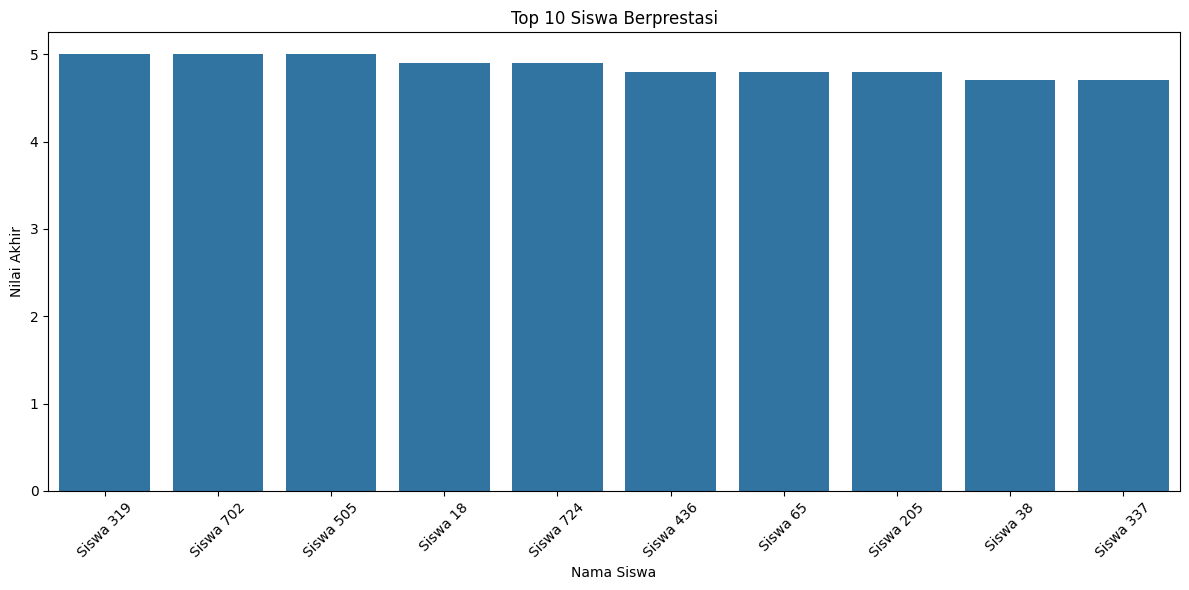

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=hasil_ranking.head(10),
    x='Nama',
    y='Nilai_Akhir'
)

plt.title('Top 10 Siswa Berprestasi')
plt.xlabel('Nama Siswa')
plt.ylabel('Nilai Akhir')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()